# Unsupervised Learning

In supervised learning, we are given $(\mathbf{x}^{(i)}, y^{(i)})$ and learn $\hat y=f(\mathbf{x})$.  In **unsupervised learning**, we only have $X=\{\mathbf{x}^{(1)},\ldots,\mathbf{x}^{(m)}\}$, with no target labels.  We learn structure from $X$.

A useful (but not universal) teaching shorthand is **$z=f(\mathbf{x})$**. The meaning of $z$ depends on our task.  Importantly, we still need a learning objective: no labels does **not** mean no objective.

| Task | Output $z$ | Representative algorithm | Question |
|---|---|---|---|
| Clustering | $z\in\{1,\ldots,K\}$ | K-Means | Which group? |
| Dimensionality reduction | $z\in\mathbb{R}^k$, $k<d$ | PCA | Can we compress? |
| Representation learning | $z\in\mathbb{R}^k$ | Truncated SVD (LSA) | What useful features can we learn? |
| Anomaly detection | $z\in\mathbb{R}$ (score) | Isolation Forest | Which sample is unusual? |
| Density estimation | $z=\hat p(\mathbf{x})$ | Gaussian Mixture Model | How is data distributed? |
| Association discovery | $\mathcal R=f(X)=\{r_1,\ldots,r_G\}$ | Apriori | What items occur together? |

**Note:** These are *tasks*, not mutually exclusive algorithm families. GMM also clusters; PCA also learns representations. Association discovery typically outputs rules for the **whole dataset**, not one $z$ per observation. Word2Vec and neural encoders are representation-learning examples, but we will focus on classical ML here.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA, TruncatedSVD
from sklearn.ensemble import IsolationForest
from sklearn.mixture import GaussianMixture
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

np.random.seed(42)

Matplotlib is building the font cache; this may take a moment.


## 1. Clustering — K-Means

Given samples $\mathbf{x}^{(i)}$, K-Means learns $K$ centroids and assigns each sample to its nearest centroid:

$$z_i=\arg\min_{k\in\{1,\ldots,K\}}\|\mathbf{x}^{(i)}-\boldsymbol\mu_k\|^2.$$

Here $z_i$ is a **cluster ID**, not a ground-truth class label.  This is only an overview; see **01 - K-Means.ipynb** for the algorithm from scratch, elbow method, and limitations.

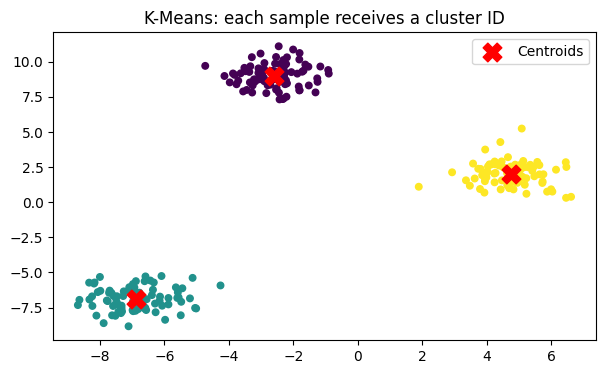

First 10 cluster IDs: [0 2 2 0 1 1 2 0 2 2]
Silhouette score: 0.869


In [2]:
X, _ = make_blobs(n_samples=250, centers=3, cluster_std=0.85, random_state=42)
model = KMeans(n_clusters=3, random_state=42, n_init=10)
z = model.fit_predict(X)

plt.figure(figsize=(7, 4))
plt.scatter(X[:, 0], X[:, 1], c=z, cmap='viridis', s=22)
plt.scatter(model.cluster_centers_[:, 0], model.cluster_centers_[:, 1],
            marker='X', s=180, c='red', label='Centroids')
plt.title('K-Means: each sample receives a cluster ID')
plt.legend(); plt.show()
print('First 10 cluster IDs:', z[:10])
print('Silhouette score:', round(silhouette_score(X, z), 3))

**Pros:** simple, fast, interpretable centroids.  **Cons:** choose $K$; sensitive to scaling, outliers, initialization, and non-spherical groups.  **Evaluation:** silhouette score and stability; do not assume a high score means the clusters are useful to the business.

## 2. Dimensionality Reduction — PCA

Given $\mathbf{x}\in\mathbb{R}^d$, PCA produces $z\in\mathbb{R}^k$ where $k<d$ by projecting onto directions of maximum variance:

$$z=W^\top(\mathbf{x}-\boldsymbol\mu).$$

The output is a **vector**, not a cluster ID. PCA is unsupervised because it learns the directions from $X$ alone.

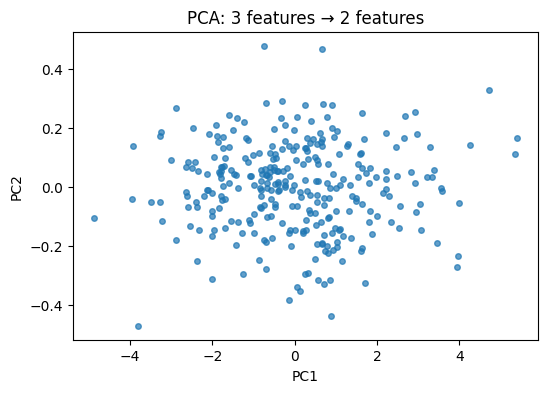

Input shape: (300, 3) Output shape: (300, 2)
Explained variance ratio: [0.987 0.008]


In [3]:
rng = np.random.default_rng(42)
t = rng.normal(size=300)
X_pca = np.column_stack([t + rng.normal(0, .15, 300),
                         2*t + rng.normal(0, .15, 300),
                         -t + rng.normal(0, .15, 300)])
X_scaled = StandardScaler().fit_transform(X_pca)
pca = PCA(n_components=2)
z_pca = pca.fit_transform(X_scaled)
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(z_pca[:, 0], z_pca[:, 1], s=16, alpha=.7)
ax.set(xlabel='PC1', ylabel='PC2', title='PCA: 3 features → 2 features')
plt.show()
print('Input shape:', X_pca.shape, 'Output shape:', z_pca.shape)
print('Explained variance ratio:', np.round(pca.explained_variance_ratio_, 3))

**Pros:** fast, removes redundancy, useful for visualization and preprocessing. **Cons:** linear, sensitive to scaling and outliers, and high variance does not necessarily mean high relevance. **Evaluation:** explained variance and downstream usefulness.

## 3. Representation Learning — Latent Semantic Analysis (Truncated SVD)

Representation learning produces a useful feature vector $z=f(\mathbf{x})\in\mathbb{R}^k$.  It **does not require** $k<d$, although this example reduces dimensions.

We will turn documents into TF-IDF vectors, then learn **latent text embeddings** using Truncated SVD. This is classical ML, **not** Word2Vec or a neural encoder. The **whole vector** is one embedding; each number is one coordinate.

/Users/chaky/Github/Python-for-Machine-Learning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: divide by zero encountered in matmul
  U = Q @ Uhat
/Users/chaky/Github/Python-for-Machine-Learning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: overflow encountered in matmul
  U = Q @ Uhat
/Users/chaky/Github/Python-for-Machine-Learning/.venv/lib/python3.9/site-packages/sklearn/utils/extmath.py:547: RuntimeWarning: invalid value encountered in matmul
  U = Q @ Uhat


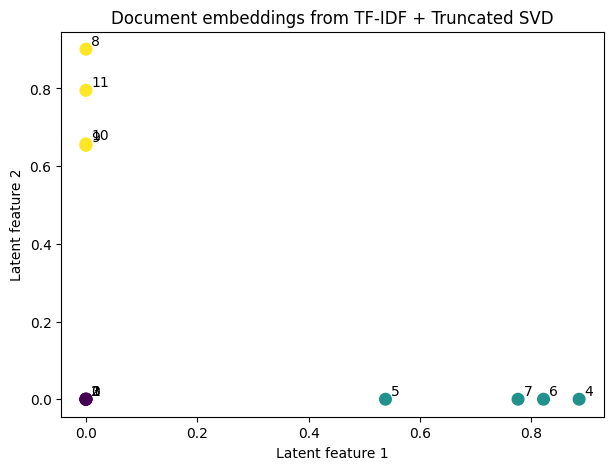

TF-IDF shape: (12, 26) Embedding shape: (12, 2)
Document 0 embedding: [0. 0.]
Documents 0, 4, 8: ['cat kitten pet animal fur', 'football soccer team goal match', 'recipe kitchen cook food dinner']


In [4]:
documents = [
    'cat kitten pet animal fur', 'dog puppy pet animal walk',
    'cat dog animal pet care', 'kitten cat purr animal',
    'football soccer team goal match', 'basketball team score match',
    'football match player team', 'soccer goal team player',
    'recipe kitchen cook food dinner', 'bake bread kitchen recipe',
    'cook meal food kitchen', 'bread food recipe dinner'
]
vectorizer = TfidfVectorizer()
X_text = vectorizer.fit_transform(documents)
svd = TruncatedSVD(n_components=2, random_state=42)
z_text = svd.fit_transform(X_text)

plt.figure(figsize=(7, 5))
plt.scatter(z_text[:, 0], z_text[:, 1], c=np.repeat([0, 1, 2], 4), cmap='viridis', s=70)
for i in range(len(documents)):
    plt.annotate(str(i), (z_text[i, 0], z_text[i, 1]), xytext=(4, 3), textcoords='offset points')
plt.title('Document embeddings from TF-IDF + Truncated SVD')
plt.xlabel('Latent feature 1'); plt.ylabel('Latent feature 2'); plt.show()
print('TF-IDF shape:', X_text.shape, 'Embedding shape:', z_text.shape)
print('Document 0 embedding:', np.round(z_text[0], 3))
print('Documents 0, 4, 8:', [documents[i] for i in (0, 4, 8)])

**Pros:** useful numerical features for retrieval, visualization, or clustering; no manually labeled topics required. **Cons:** embedding dimensions are not necessarily human-interpretable; TF-IDF + SVD misses some semantic/contextual meaning. **Evaluation:** nearest-neighbor relevance, downstream performance, or qualitative inspection. **Important:** PCA is also representation learning; these task categories overlap.

## 4. Anomaly Detection — Isolation Forest

Isolation Forest randomly selects a feature and a split threshold within that feature's observed range at each node. Points that require **fewer splits** to isolate tend to be anomalous.

Here $z=f(\mathbf{x})$ is an **anomaly score**, not a cluster ID. In scikit-learn, `decision_function` is **lower for more anomalous observations**; `predict` returns $-1$ for outliers and $+1$ for inliers.

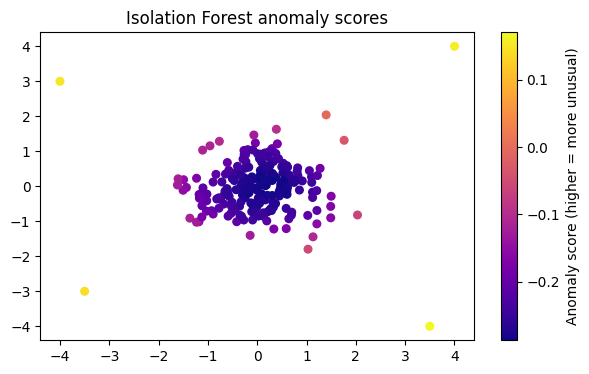

Detected outliers: 4
Last 4 scores: [0.156 0.15  0.17  0.142]


In [5]:
rng = np.random.default_rng(42)
normal = rng.normal(loc=0, scale=.7, size=(200, 2))
outliers = np.array([[4, 4], [-4, 3], [3.5, -4], [-3.5, -3]])
X_anomaly = np.vstack([normal, outliers])
iso = IsolationForest(contamination=4/204, random_state=42)
iso.fit(X_anomaly)
score = -iso.decision_function(X_anomaly)  # larger = more anomalous (our convention)
labels = iso.predict(X_anomaly)
plt.figure(figsize=(7, 4))
plt.scatter(X_anomaly[:, 0], X_anomaly[:, 1], c=score, cmap='plasma', s=30)
plt.colorbar(label='Anomaly score (higher = more unusual)')
plt.title('Isolation Forest anomaly scores'); plt.show()
print('Detected outliers:', (labels == -1).sum())
print('Last 4 scores:', np.round(score[-4:], 3))

**Pros:** efficient, works on multivariate data, no explicit distance calculation. **Cons:** threshold/contamination must be chosen; axis-aligned random splits can be sensitive to feature representation; unusual does not automatically mean erroneous. **Evaluation:** inspect top-ranked anomalies; if labels later become available, use precision/recall. Note that `contamination` helps choose a threshold, not learn ground-truth anomalies.

## 5. Density Estimation — Gaussian Mixture Model (GMM)

A GMM estimates a probability **density**:

$$z=\hat p(\mathbf{x})=\sum_{k=1}^{K}\pi_k\,\mathcal N(\mathbf{x}\mid\boldsymbol\mu_k,\Sigma_k).$$

The same GMM can also output **soft cluster membership probabilities**. For continuous variables, $p(x)$ is a density, **not** $P(X=x)$.

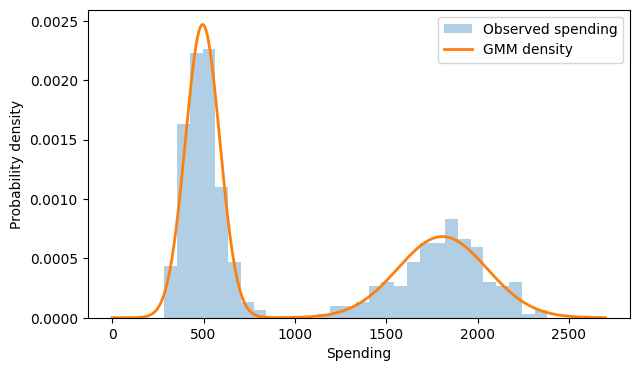

Density at 500, 1100, 1800: [2.467e-03 1.000e-05 6.830e-04]
Cluster probabilities at 1100: [[0. 1.]]


In [6]:
rng = np.random.default_rng(42)
spending = np.r_[rng.normal(500, 100, 250), rng.normal(1800, 250, 180)].reshape(-1, 1)
gmm = GaussianMixture(n_components=2, random_state=42).fit(spending)
xx = np.linspace(0, 2700, 400).reshape(-1, 1)
density = np.exp(gmm.score_samples(xx))  # score_samples returns log density
plt.figure(figsize=(7, 4))
plt.hist(spending[:, 0], bins=30, density=True, alpha=.35, label='Observed spending')
plt.plot(xx[:, 0], density, linewidth=2, label='GMM density')
plt.xlabel('Spending'); plt.ylabel('Probability density'); plt.legend(); plt.show()
print('Density at 500, 1100, 1800:', np.round(np.exp(gmm.score_samples(np.array([[500], [1100], [1800]]))), 6))
print('Cluster probabilities at 1100:', np.round(gmm.predict_proba([[1100]]), 3))

**Pros:** flexible multimodal density, soft cluster assignments, useful for likelihood-based analysis. **Cons:** assumes a Gaussian mixture, requires number of components, can be sensitive to initialization, covariance choice, and outliers. **Evaluation:** held-out log-likelihood, AIC/BIC, and whether the density captures observed patterns.

## 6. Association Discovery — Apriori

Association discovery finds **rules** such as $\{\text{Bread}\}\Rightarrow\{\text{Butter}\}$ from a dataset of transactions. Its output is $\mathcal R=f(X)$, a **set of rules**, rather than one output per customer.

- **Support** $P(A\cap B)$: how often both occur.
- **Confidence** $P(B\mid A)$: how often $B$ occurs when $A$ occurs.
- **Lift** $P(B\mid A)/P(B)$: whether co-occurrence exceeds the baseline frequency of $B$.

Below is a **small, transparent Apriori implementation** using standard Python. It generates frequent itemsets level by level and prunes candidates whose subsets are not frequent.

In [7]:
from itertools import combinations

transactions = [
    {'bread', 'butter', 'milk'}, {'bread', 'butter'},
    {'bread', 'milk'}, {'bread', 'butter', 'milk'},
    {'butter', 'milk'}, {'bread', 'butter'},
    {'bread', 'butter', 'milk'}, {'eggs', 'milk'}
]

def apriori(transactions, min_support=0.3):
    n = len(transactions)
    items = sorted(set().union(*transactions))
    level = {frozenset([item]) for item in items}
    frequent = {}
    k = 1
    while level:
        counts = {s: sum(s.issubset(t) for t in transactions) for s in level}
        kept = {s for s, count in counts.items() if count / n >= min_support}
        frequent.update({s: counts[s] / n for s in kept})
        k += 1
        unions = {a | b for a in kept for b in kept if len(a | b) == k}
        level = {s for s in unions if all(frozenset(sub) in kept for sub in combinations(s, k-1))}
    return frequent

frequent = apriori(transactions, min_support=.3)
print('Frequent itemsets:')
for items, support in sorted(frequent.items(), key=lambda t: (len(t[0]), sorted(t[0]))):
    print(sorted(items), 'support =', round(support, 3))

Frequent itemsets:
['bread'] support = 0.75
['butter'] support = 0.75
['milk'] support = 0.75
['bread', 'butter'] support = 0.625
['bread', 'milk'] support = 0.5
['butter', 'milk'] support = 0.5
['bread', 'butter', 'milk'] support = 0.375


In [8]:
rules = []
for itemset, support_ab in frequent.items():
    if len(itemset) < 2:
        continue
    for r in range(1, len(itemset)):
        for left_tuple in combinations(sorted(itemset), r):
            A = frozenset(left_tuple)
            B = itemset - A
            confidence = support_ab / frequent[A]
            lift = confidence / frequent[B]
            if confidence >= .7:
                rules.append((sorted(A), sorted(B), support_ab, confidence, lift))
for A, B, sup, conf, lift in sorted(rules, key=lambda x: -x[4]):
    print(f'{A} => {B}: support={sup:.2f}, confidence={conf:.2f}, lift={lift:.2f}')

['bread'] => ['butter']: support=0.62, confidence=0.83, lift=1.11
['butter'] => ['bread']: support=0.62, confidence=0.83, lift=1.11
['bread', 'milk'] => ['butter']: support=0.38, confidence=0.75, lift=1.00
['butter', 'milk'] => ['bread']: support=0.38, confidence=0.75, lift=1.00


**Pros:** interpretable rules; useful for market-basket analysis and co-occurrence discovery. **Cons:** potentially huge numbers of rules, sensitive to thresholds, and associations do **not** establish causation. **Evaluation:** support, confidence, lift, and practical usefulness. High confidence alone may reflect a common consequent.

## 7. How to Choose and Evaluate?

| If you want to... | Start with | Check |
|---|---|---|
| Segment customers | K-Means | Scaling, $K$, silhouette, stability |
| Visualize many features | PCA | Explained variance, scaling |
| Learn text features | TF-IDF + Truncated SVD | Similarity/retrieval quality |
| Flag unusual records | Isolation Forest | Top-ranked cases, threshold, false alarms |
| Estimate probability density | GMM | Held-out likelihood, components |
| Find market-basket rules | Apriori | Support, confidence, lift |

**Before modeling:** inspect missing values, feature scales, duplicates, outliers, and whether the data represent the question you care about. Most of these methods are sensitive to how you represent $X$.

**Crucial:** no labels does **not** mean no evaluation. Internal metrics can help, but they cannot prove that a pattern is meaningful or causal. Compare against a simple baseline, check stability, and use domain judgment.